# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Benedictus Ryu Gunawan | 5054251001 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, scipy, dll)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')
np.random.seed(RANDOM_STATE)

In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data,
# statistik deskriptif, jumlah missing value, dan jumlah baris duplikat.
# Perhatikan apakah ada kolom yang seluruhnya kosong.
df = pd.read_csv('Live.csv')

print('Jumlah baris dan kolom:', df.shape)
print('\nTipe data:')
display(df.dtypes)

print('\nStatistik deskriptif:')
display(df.describe())

print('\nJumlah missing value per kolom:')
display(df.isna().sum())

print('Jumlah baris duplikat (seluruh kolom):', df.duplicated().sum())
print('Kolom yang seluruhnya kosong:', [c for c in df.columns if df[c].isna().all()])

Jumlah baris dan kolom: (7050, 16)

Tipe data:


status_id             int64
status_type          object
status_published     object
num_reactions         int64
num_comments          int64
num_shares            int64
num_likes             int64
num_loves             int64
num_wows              int64
num_hahas             int64
num_sads              int64
num_angrys            int64
Column1             float64
Column2             float64
Column3             float64
Column4             float64
dtype: object


Statistik deskriptif:


,status_id,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
count,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,0.0,0.0,0.0,0.0
mean,3525.500000,230.117163,224.356028,40.022553,215.043121,12.728652,1.289362,0.696454,0.243688,0.113191,NaN,NaN,NaN,NaN
std,2035.304031,462.625309,889.636820,131.599965,449.472357,39.972930,8.719650,3.957183,1.597156,0.726812,NaN,NaN,NaN,NaN
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
25%,1763.250000,17.000000,0.000000,0.000000,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
50%,3525.500000,59.500000,4.000000,0.000000,58.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
75%,5287.750000,219.000000,23.000000,4.000000,184.750000,3.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
max,7050.000000,4710.000000,20990.000000,3424.000000,4710.000000,657.000000,278.000000,157.000000,51.000000,31.000000,NaN,NaN,NaN,NaN



Jumlah missing value per kolom:


status_id              0
status_type            0
status_published       0
num_reactions          0
num_comments           0
num_shares             0
num_likes              0
num_loves              0
num_wows               0
num_hahas              0
num_sads               0
num_angrys             0
Column1             7050
Column2             7050
Column3             7050
Column4             7050
dtype: int64

Jumlah baris duplikat (seluruh kolom): 0
Kolom yang seluruhnya kosong: ['Column1', 'Column2', 'Column3', 'Column4']


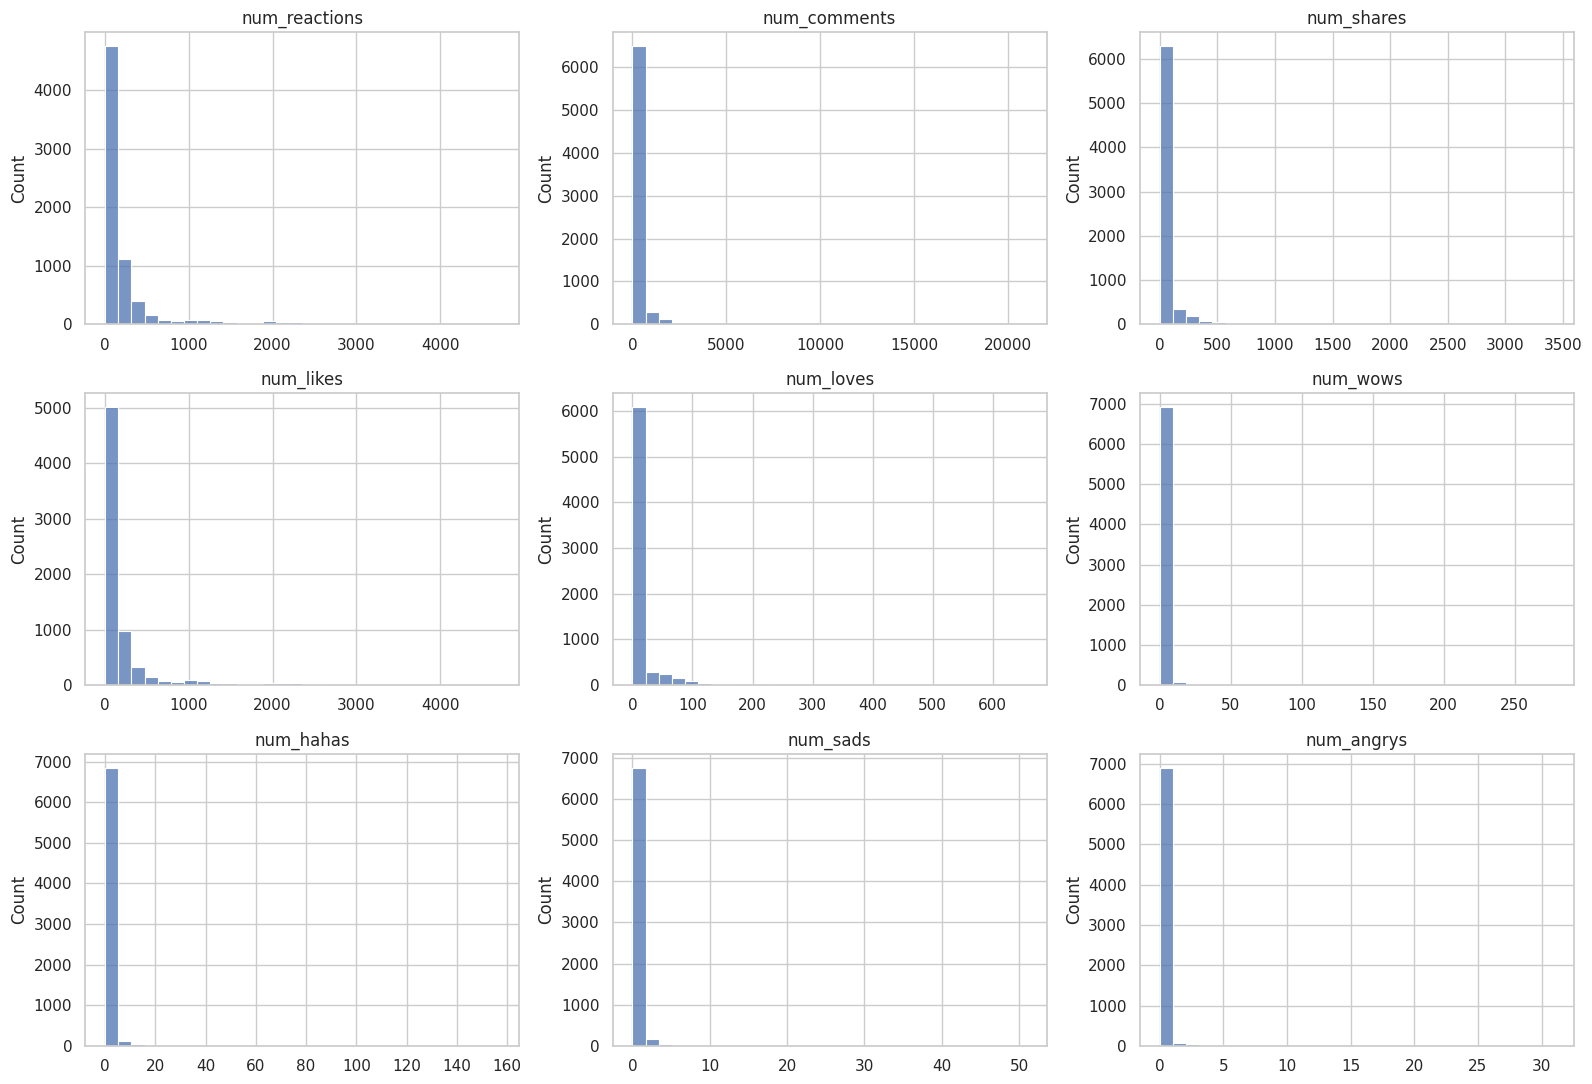

Ringkasan bentuk distribusi fitur hitungan:


,Skewness,Proporsi nol,Minimum,Maksimum
num_reactions,3.738,0.017,0,4710
num_comments,9.029,0.301,0,20990
num_shares,7.099,0.555,0,3424
num_likes,3.919,0.018,0,4710
num_loves,6.005,0.600,0,657
num_wows,18.247,0.753,0,278
num_hahas,20.306,0.839,0,157
num_sads,17.579,0.914,0,51
num_angrys,19.507,0.940,0,31


In [3]:
# Tampilkan distribusi fitur hitungan (histogram atau boxplot).
# Perhatikan skewness, proporsi nilai nol, dan perbedaan skala antar fitur
# (misalnya num_comments vs num_angrys), karena ini penting untuk tahap preprocessing.
count_cols = [
    'num_reactions', 'num_comments', 'num_shares', 'num_likes',
    'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys',
]

fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, col in zip(axes.ravel(), count_cols):
    sns.histplot(df[col], bins=30, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

eda_numeric = pd.DataFrame({
    'Skewness': df[count_cols].skew(),
    'Proporsi nol': (df[count_cols] == 0).mean(),
    'Minimum': df[count_cols].min(),
    'Maksimum': df[count_cols].max(),
})
print('Ringkasan bentuk distribusi fitur hitungan:')
display(eda_numeric.round(3))

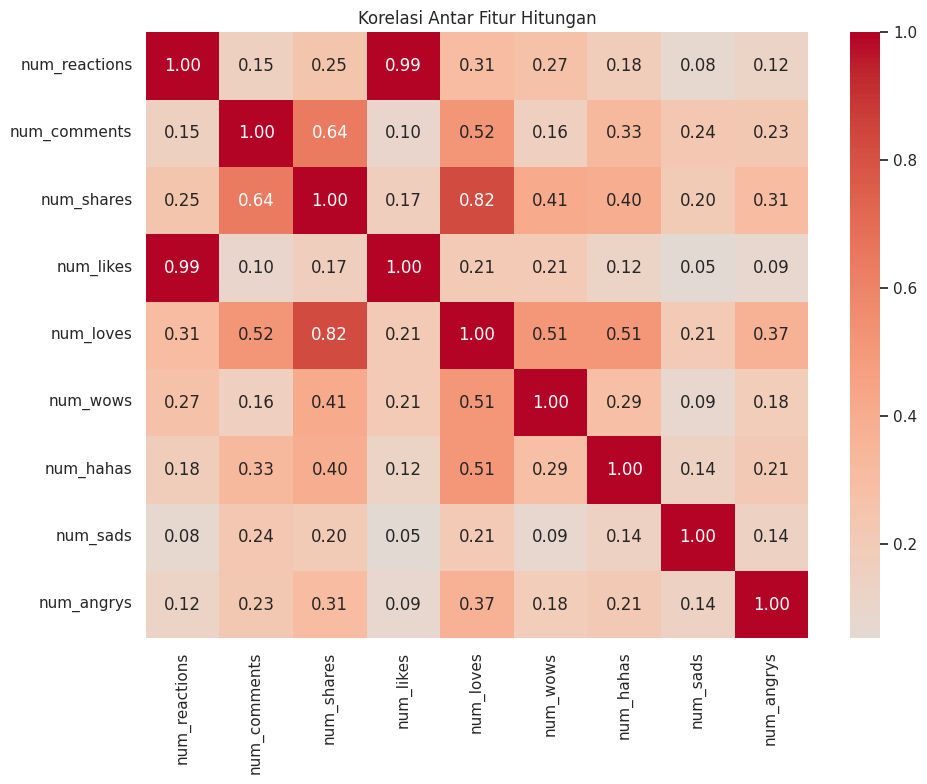

Proporsi baris dengan num_reactions == jumlah seluruh reaksi: 0.9987234042553191
Korelasi num_likes dengan num_reactions: 0.9949


In [4]:
# Tampilkan heatmap korelasi antar fitur hitungan.
# Perhatikan fitur-fitur yang berkorelasi sangat tinggi atau saling berkaitan secara
# definisi (redundan), karena memengaruhi perhitungan jarak pada clustering.
plt.figure(figsize=(10, 8))
sns.heatmap(df[count_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Korelasi Antar Fitur Hitungan')
plt.tight_layout()
plt.show()

reaction_sum = df[['num_likes', 'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']].sum(axis=1)
print('Proporsi baris dengan num_reactions == jumlah seluruh reaksi:',
      np.isclose(reaction_sum, df['num_reactions']).mean())
print('Korelasi num_likes dengan num_reactions:',
      round(df['num_likes'].corr(df['num_reactions']), 4))

Ringkasan posting per tahun:


,year,jumlah_posting,proporsi_posting,proporsi_ada_reaksi_emoji
0,2012,589,8.35%,0.00%
1,2013,500,7.09%,0.00%
2,2014,233,3.30%,0.00%
3,2015,337,4.78%,0.00%
4,2016,588,8.34%,68.03%
5,2017,2253,31.96%,54.19%
6,2018,2550,36.17%,57.76%


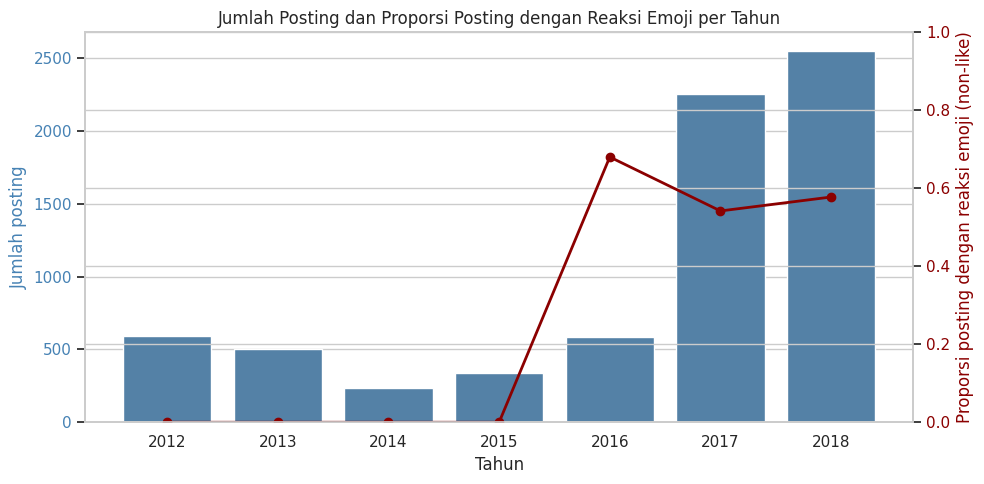

In [5]:
# Ubah kolom status_published menjadi datetime.
# Tampilkan jumlah posting dan proporsi posting yang memiliki reaksi emoji pada setiap tahun.
# Amati apakah ada perubahan pola dari tahun ke tahun.
df['status_published'] = pd.to_datetime(df['status_published'], format='%m/%d/%Y %H:%M')
df['year'] = df['status_published'].dt.year

emoji_cols = ['num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
df['punya_reaksi_emoji'] = df[emoji_cols].sum(axis=1) > 0

year_summary = df.groupby('year').agg(
    jumlah_posting=('status_id', 'size'),
).reset_index()
year_summary['proporsi_posting'] = year_summary['jumlah_posting'] / len(df)
year_summary['proporsi_ada_reaksi_emoji'] = (
    df.groupby('year')['punya_reaksi_emoji'].mean().values
)

print('Ringkasan posting per tahun:')
display(year_summary.style.format({
    'proporsi_posting': '{:.2%}',
    'proporsi_ada_reaksi_emoji': '{:.2%}',
}))

x_pos = np.arange(len(year_summary))
fig, ax1 = plt.subplots(figsize=(10, 5))
sns.barplot(x=x_pos, y=year_summary['jumlah_posting'], color='steelblue', ax=ax1)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(year_summary['year'])
ax1.set_xlabel('Tahun')
ax1.set_ylabel('Jumlah posting', color='steelblue')
ax1.tick_params(axis='y', labelcolor='steelblue')

ax2 = ax1.twinx()
ax2.plot(
    x_pos, year_summary['proporsi_ada_reaksi_emoji'],
    color='darkred', marker='o', linewidth=2,
)
ax2.set_ylabel('Proporsi posting dengan reaksi emoji (non-like)', color='darkred')
ax2.tick_params(axis='y', labelcolor='darkred')
ax2.set_ylim(0, 1)

plt.title('Jumlah Posting dan Proporsi Posting dengan Reaksi Emoji per Tahun')
plt.tight_layout()
plt.show()

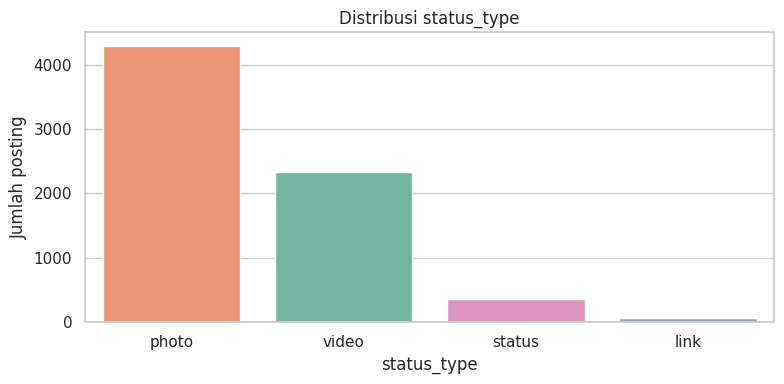

Median fitur engagement per status_type:


,num_likes,num_comments,num_shares,num_reactions
status_type,,,,
link,48.0,1.0,0.0,50.0
photo,34.0,2.0,0.0,34.0
status,117.0,10.0,0.0,120.0
video,117.0,39.0,12.0,160.0


In [6]:
# Tampilkan distribusi status_type dalam bentuk bar plot.
# Bandingkan median num_likes, num_comments, dan num_shares untuk setiap status_type.
plt.figure(figsize=(8, 4))
sns.countplot(
    data=df, x='status_type', order=df['status_type'].value_counts().index,
    hue='status_type', legend=False, palette='Set2',
)
plt.title('Distribusi status_type')
plt.xlabel('status_type')
plt.ylabel('Jumlah posting')
plt.tight_layout()
plt.show()

status_summary = df.groupby('status_type')[['num_likes', 'num_comments', 'num_shares', 'num_reactions']].median()
print('Median fitur engagement per status_type:')
display(status_summary)

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

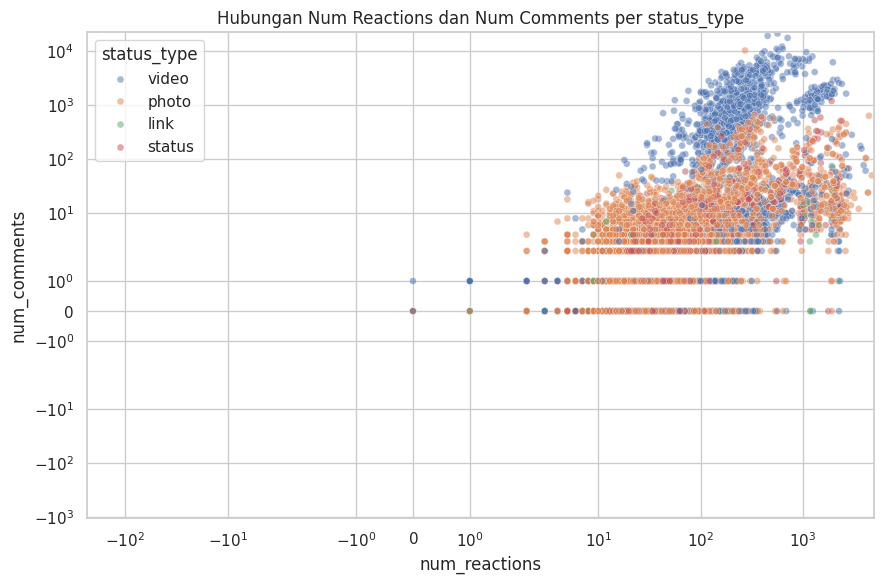

Median engagement per tahun:


,num_reactions,num_comments,num_shares
year,,,
2012,19.0,5.0,0.0
2013,55.0,3.0,0.0
2014,437.0,10.0,1.0
2015,1566.0,12.0,1.0
2016,143.5,6.0,0.0
2017,43.0,3.0,0.0
2018,57.0,2.5,1.0


In [7]:
# EDA tambahan: hubungan num_reactions dan num_comments, diwarnai status_type.
# Skala symlog dipakai agar nilai nol dan nilai ekstrem tetap terlihat.
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df, x='num_reactions', y='num_comments',
    hue='status_type', alpha=0.5, s=25,
)
plt.xscale('symlog')
plt.yscale('symlog')
plt.title('Hubungan Num Reactions dan Num Comments per status_type')
plt.tight_layout()
plt.show()

# EDA tambahan: ringkasan engagement per tahun (median).
year_engagement = df.groupby('year')[['num_reactions', 'num_comments', 'num_shares']].median()
print('Median engagement per tahun:')
display(year_engagement)

**Temuan EDA singkat:**

1. Dataset berisi 7.050 baris dan 16 kolom. Kolom `Column1`–`Column4` seluruhnya kosong. Tidak ada missing value pada kolom lain, tetapi terdapat 54 baris duplikat jika `status_id` (yang selalu unik) diabaikan.
2. Seluruh fitur hitungan sangat miring (*right-skewed*): skewness 3,74–20,31. Banyak nilai nol, terutama pada reaksi emoji (`num_loves` 60%, `num_wows` 75%, `num_hahas` 84%, `num_sads` 91%, `num_angrys` 94%), sedangkan `num_reactions` hanya 1,7% nol. Skala antar fitur juga jauh berbeda.
3. `num_reactions` hampir selalu sama dengan jumlah seluruh reaksi (99,87% baris; selisih maksimum 4) dan berkorelasi 0,995 dengan `num_likes`. Artinya `num_reactions` dan `num_likes` redundan dengan komponen reaksi lainnya.
4. Reaksi emoji non-like baru muncul mulai tahun 2016 (0% pada 2012–2015, lalu 68,0% pada 2016 dan sekitar 54–58% pada 2017–2018). Ini bertepatan dengan diperkenalkannya Facebook Reactions pada Februari 2016. Posting paling banyak berasal dari 2017–2018 (68,1% data).
5. `video` memiliki median komentar (39) dan share (12) tertinggi, jauh di atas `photo` (2 dan 0). Sebaliknya `status` punya median like cukup tinggi (117) tetapi share 0. Ini menunjukkan `status_type` berpotensi membantu interpretasi cluster, meskipun tidak boleh dipakai sebagai fitur.
6. Scatter `num_reactions` vs `num_comments` menunjukkan kelompok video cenderung memiliki komentar tinggi, sedangkan banyak photo menumpuk di area engagement rendah.

# 2. Preprocessing

In [8]:
# Hapus kolom yang seluruhnya kosong.
# Periksa dan tangani baris duplikat (ingat bahwa status_id selalu unik untuk tiap baris).
# Periksa juga missing value dan outlier ekstrem, lalu tentukan penanganannya.
empty_cols = [c for c in df.columns if df[c].isna().all()]
df = df.drop(columns=empty_cols)
print('Kolom kosong yang dihapus:', empty_cols)

before = len(df)
df = df.drop_duplicates(subset=[c for c in df.columns if c != 'status_id']).reset_index(drop=True)
print(f'Baris duplikat dihapus: {before - len(df)}')
print('Jumlah baris setelah pembersihan:', len(df))
print('Total missing value:', int(df.isna().sum().sum()))

selected_raw = ['num_likes', 'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys', 'num_comments', 'num_shares']
outlier_rows = []
for col in selected_raw:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_atas = q3 + 1.5 * iqr
    jumlah = int((df[col] > batas_atas).sum())
    outlier_rows.append({
        'Fitur': col,
        'Batas atas IQR': batas_atas,
        'Jumlah outlier': jumlah,
        'Proporsi outlier': jumlah / len(df),
    })

outlier_df = pd.DataFrame(outlier_rows)
print('Pemeriksaan outlier ekstrem (metode IQR):')
display(outlier_df.style.format({'Batas atas IQR': '{:,.1f}', 'Proporsi outlier': '{:.2%}'}))
print('Outlier tidak dihapus karena merupakan posting viral yang valid, bukan kesalahan input.')

Kolom kosong yang dihapus: ['Column1', 'Column2', 'Column3', 'Column4']
Baris duplikat dihapus: 54
Jumlah baris setelah pembersihan: 6996
Total missing value: 0
Pemeriksaan outlier ekstrem (metode IQR):


,Fitur,Batas atas IQR,Jumlah outlier,Proporsi outlier
0,num_likes,429.5,754,10.78%
1,num_loves,7.5,1303,18.62%
2,num_wows,0.0,1702,24.33%
3,num_hahas,0.0,1117,15.97%
4,num_sads,0.0,598,8.55%
5,num_angrys,0.0,420,6.00%
6,num_comments,55.6,1365,19.51%
7,num_shares,10.0,1382,19.75%


Outlier tidak dihapus karena merupakan posting viral yang valid, bukan kesalahan input.


In [9]:
# Pisahkan status_type dan status_published (untuk interpretasi cluster pada tahap evaluasi)
# dari fitur yang akan dipakai untuk clustering.
# Hapus kolom yang tidak relevan untuk clustering (misalnya status_id).
# Periksa apakah ada fitur yang redundan atau yang sebagian besar bernilai nol.
# Pilih fitur yang akan dipakai untuk clustering. Pertimbangkan untuk menggabungkan fitur yang sparse.
meta = df[['status_type', 'status_published', 'year']].copy()

# Reaksi emoji yang sparse digabung menjadi tiga kelompok yang lebih bermakna.
feature_data = pd.DataFrame({
    'num_positive': df['num_likes'] + df['num_loves'] + df['num_wows'],
    'num_hahas': df['num_hahas'],
    'num_negative': df['num_sads'] + df['num_angrys'],
    'num_comments': df['num_comments'],
    'num_shares': df['num_shares'],
})
feature_cols = feature_data.columns.tolist()

print('Fitur yang dipilih untuk clustering:', feature_cols)
print('\nStatistik deskriptif fitur clustering:')
display(feature_data.describe())

print('\nProporsi nilai nol pada fitur hasil penggabungan:')
display((feature_data == 0).mean().rename('Proporsi nol').to_frame().T)

print('\nKorelasi fitur terpilih dengan num_reactions (untuk memeriksa redundansi):')
display(pd.concat([df[['num_reactions']], feature_data], axis=1).corr()['num_reactions'].to_frame().T)

# Data bersih untuk interpretasi cluster (masih berisi fitur asli).
df_clean = df.copy()

Fitur yang dipilih untuk clustering: ['num_positive', 'num_hahas', 'num_negative', 'num_comments', 'num_shares']

Statistik deskriptif fitur clustering:


,num_positive,num_hahas,num_negative,num_comments,num_shares
count,6996.000000,6996.000000,6996.000000,6996.000000,6996.000000
mean,224.047170,0.698256,0.342910,225.648799,40.275872
std,452.046987,3.971738,1.721095,892.922206,132.072584
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,17.000000,0.000000,0.000000,0.000000,0.000000
50%,58.000000,0.000000,0.000000,4.000000,0.000000
75%,214.000000,0.000000,0.000000,22.250000,4.000000
max,4710.000000,157.000000,51.000000,20990.000000,3424.000000



Proporsi nilai nol pada fitur hasil penggabungan:


,num_positive,num_hahas,num_negative,num_comments,num_shares
Proporsi nol,0.016867,0.840337,0.886507,0.302459,0.558176



Korelasi fitur terpilih dengan num_reactions (untuk memeriksa redundansi):


,num_reactions,num_positive,num_hahas,num_negative,num_comments,num_shares
num_reactions,1.0,0.999949,0.17963,0.125075,0.156146,0.259594


**Fitur yang dipilih untuk clustering:** `num_positive`, `num_hahas`, `num_negative`, `num_comments`, dan `num_shares`.

Alasannya:
- `num_reactions` **tidak dipakai** karena hampir selalu sama persis dengan jumlah enam kolom reaksi (redundan secara definisi). `num_likes` juga tidak dipakai terpisah karena korelasinya 0,995 dengan `num_reactions`.
- Kolom reaksi emoji yang sangat sparse digabung: `num_likes + num_loves + num_wows` menjadi `num_positive`, `num_sads + num_angrys` menjadi `num_negative`, sedangkan `num_hahas` tetap berdiri sendiri karena maknanya berbeda (humor). Penggabungan ini mengurangi jumlah kolom yang hampir seluruhnya nol tanpa membuang informasi jenis reaksi.
- `num_comments` dan `num_shares` dipertahankan karena mengukur bentuk engagement yang berbeda (diskusi dan penyebaran) serta tidak redundan dengan reaksi.
- `status_id` dihapus karena hanya identitas. `status_type` dan `status_published` disimpan terpisah sebagai metadata untuk interpretasi cluster, **bukan** sebagai fitur.

Perbandingan skewness sebelum dan sesudah log1p:


,Skewness sebelum log1p,Skewness sesudah log1p
num_positive,3.75,-0.04
num_hahas,20.24,3.12
num_negative,13.61,3.70
num_comments,8.99,1.05
num_shares,7.07,1.53


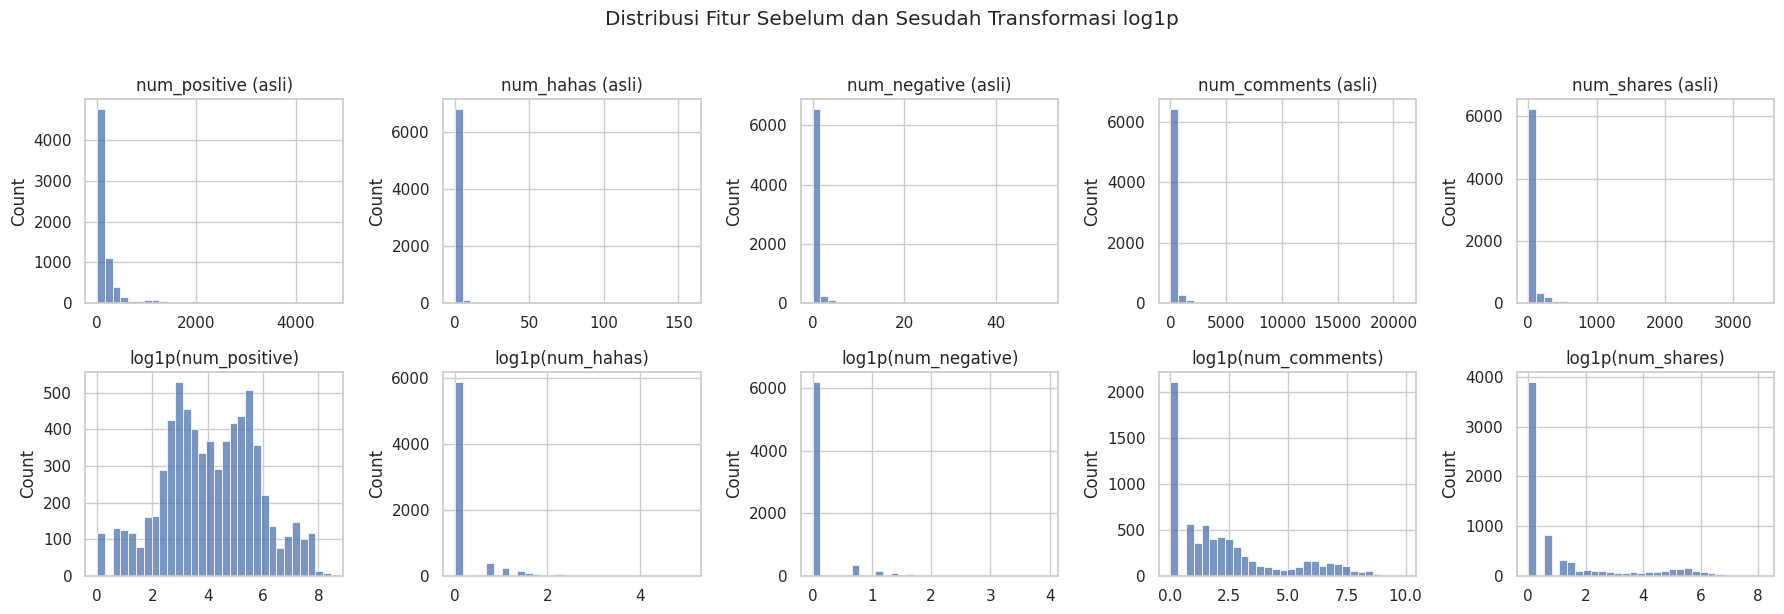

In [10]:
# Fitur hitungan pada dataset ini sangat miring (skewed). Terapkan transformasi log1p
# pada fitur yang dipilih. Tampilkan distribusi fitur sebelum dan sesudah transformasi.
X_log = np.log1p(feature_data)

skew_df = pd.DataFrame({
    'Skewness sebelum log1p': feature_data.skew(),
    'Skewness sesudah log1p': X_log.skew(),
})
print('Perbandingan skewness sebelum dan sesudah log1p:')
display(skew_df.round(2))

fig, axes = plt.subplots(2, len(feature_cols), figsize=(18, 6))
for j, col in enumerate(feature_cols):
    sns.histplot(feature_data[col], bins=30, ax=axes[0, j])
    axes[0, j].set_title(f'{col} (asli)')
    axes[0, j].set_xlabel('')

    sns.histplot(X_log[col], bins=30, ax=axes[1, j])
    axes[1, j].set_title(f'log1p({col})')
    axes[1, j].set_xlabel('')

plt.suptitle('Distribusi Fitur Sebelum dan Sesudah Transformasi log1p', y=1.02)
plt.tight_layout()
plt.show()

In [11]:
# Lakukan feature scaling (misalnya StandardScaler) pada fitur hasil transformasi log
# dan simpan hasilnya (X_log_scaled).
# Simpan juga versi lain untuk keperluan perbandingan pada bagian 3.1:
# - X_raw: fitur mentah tanpa transformasi dan tanpa scaling
# - X_raw_scaled: fitur mentah dengan scaling saja
X_raw = feature_data.values
X_raw_scaled = StandardScaler().fit_transform(X_raw)
X_log_scaled = StandardScaler().fit_transform(np.log1p(X_raw))

print('Shape X_raw        :', X_raw.shape)
print('Shape X_raw_scaled :', X_raw_scaled.shape)
print('Shape X_log_scaled :', X_log_scaled.shape)
print('\nRata-rata X_log_scaled per fitur:', np.round(X_log_scaled.mean(axis=0), 10))
print('Standar deviasi X_log_scaled per fitur:', np.round(X_log_scaled.std(axis=0), 4))

Shape X_raw        : (6996, 5)
Shape X_raw_scaled : (6996, 5)
Shape X_log_scaled : (6996, 5)

Rata-rata X_log_scaled per fitur: [-0. -0.  0. -0.  0.]
Standar deviasi X_log_scaled per fitur: [1. 1. 1. 1. 1.]


**Catatan preprocessing:** transformasi `log1p` menurunkan skewness secara drastis (misalnya `num_positive` dari 3,75 menjadi -0,04 dan `num_comments` dari 8,99 menjadi 1,05). Setelah itu `StandardScaler` membuat semua fitur memiliki skala sebanding, sehingga fitur dengan nilai besar seperti komentar tidak mendominasi perhitungan jarak. Outlier ekstrem dipertahankan karena merupakan posting viral yang valid; `log1p` sudah cukup meredam pengaruhnya.

# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [12]:
# Latih K-Means dengan jumlah cluster yang sama (misalnya k=3) pada tiga versi data:
# (1) X_raw (mentah tanpa scaling), (2) X_raw_scaled (mentah dengan scaling), dan
# (3) X_log_scaled (log dan scaling).
# Gunakan random_state dan n_init yang sama agar perbandingan adil.
k_compare = 3

models_compare = {
    'X_raw (tanpa transformasi, tanpa scaling)': KMeans(
        n_clusters=k_compare, random_state=RANDOM_STATE, n_init=10
    ).fit(X_raw),
    'X_raw_scaled (scaling saja)': KMeans(
        n_clusters=k_compare, random_state=RANDOM_STATE, n_init=10
    ).fit(X_raw_scaled),
    'X_log_scaled (log1p + scaling)': KMeans(
        n_clusters=k_compare, random_state=RANDOM_STATE, n_init=10
    ).fit(X_log_scaled),
}

variance_df = pd.DataFrame({
    'Fitur': feature_cols,
    'Varians data mentah': X_raw.var(axis=0),
    'Varians setelah scaling': X_raw_scaled.var(axis=0),
})
print('Varians fitur pada data mentah vs setelah scaling:')
display(variance_df.round(2))
print('Proporsi varians data mentah yang disumbang num_comments:',
      round(X_raw.var(axis=0)[feature_cols.index('num_comments')] / X_raw.var(axis=0).sum(), 4))

Varians fitur pada data mentah vs setelah scaling:


,Fitur,Varians data mentah,Varians setelah scaling
0,num_positive,204317.27,1.0
1,num_hahas,15.77,1.0
2,num_negative,2.96,1.0
3,num_comments,797196.10,1.0
4,num_shares,17440.67,1.0


Proporsi varians data mentah yang disumbang num_comments: 0.7824


In [13]:
# Bandingkan ketiga hasil tersebut: jumlah anggota tiap cluster dan Silhouette Score.
# Hitung Silhouette ketiganya pada ruang yang sama (misalnya X_log_scaled) agar perbandingannya adil.
# Amati fitur mana yang mendominasi varians pada data tanpa scaling, dan apakah ada cluster
# yang sangat kecil atau sangat besar.
comparison_rows = []
for name, model in models_compare.items():
    labels = model.labels_
    comparison_rows.append({
        'Data': name,
        'Ukuran cluster': ', '.join(map(str, np.bincount(labels))),
        'Cluster terkecil': int(np.bincount(labels).min()),
        'Silhouette (ruang X_log_scaled)': silhouette_score(X_log_scaled, labels),
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.style.format({'Silhouette (ruang X_log_scaled)': '{:.4f}'}))

,Data,Ukuran cluster,Cluster terkecil,Silhouette (ruang X_log_scaled)
0,"X_raw (tanpa transformasi, tanpa scaling)","6392, 137, 467",137,0.3429
1,X_raw_scaled (scaling saja),"6322, 388, 286",286,0.2604
2,X_log_scaled (log1p + scaling),"990, 3688, 2318",990,0.4106


## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [14]:
# Latih K-Means pada X_log_scaled untuk rentang k tertentu (misalnya k = 2 sampai 10).
# Simpan nilai inertia untuk setiap k.
k_values = list(range(2, 11))
inertias = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_log_scaled)
    inertias.append(km.inertia_)

elbow_df = pd.DataFrame({'k': k_values, 'Inertia': inertias})
elbow_df['Penurunan dari k sebelumnya'] = elbow_df['Inertia'].pct_change().abs()
print('Nilai inertia untuk setiap k:')
display(elbow_df.style.format({
    'Inertia': '{:,.1f}',
    'Penurunan dari k sebelumnya': '{:.2%}',
}))

Nilai inertia untuk setiap k:


,k,Inertia,Penurunan dari k sebelumnya
0,2,"18,100.2",nan%
1,3,"13,167.1",27.25%
2,4,"10,434.1",20.76%
3,5,"8,826.0",15.41%
4,6,"7,829.2",11.29%
5,7,"6,932.1",11.46%
6,8,"6,294.4",9.20%
7,9,"5,745.5",8.72%
8,10,"5,334.9",7.15%


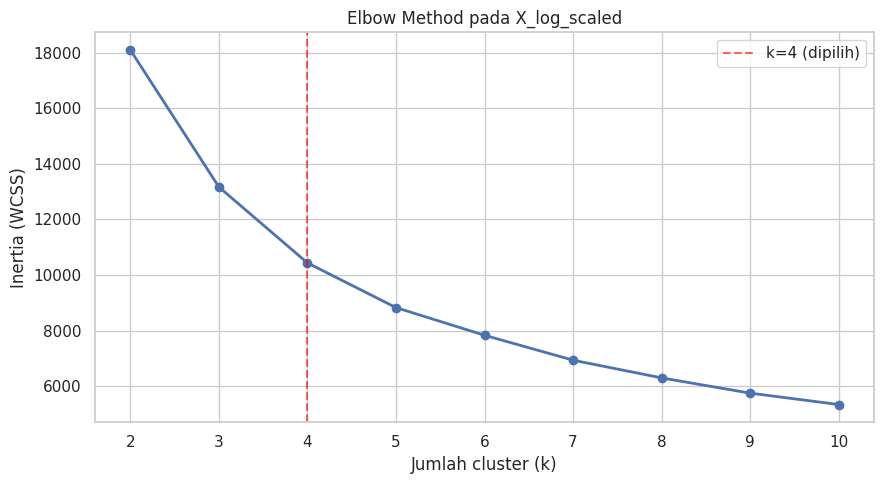

In [15]:
# Plot grafik Elbow (k vs inertia).
# Amati pada nilai k berapa terbentuk "siku".
plt.figure(figsize=(9, 5))
plt.plot(k_values, inertias, marker='o', linewidth=2)
plt.axvline(4, color='red', linestyle='--', alpha=0.6, label='k=4 (dipilih)')
plt.title('Elbow Method pada X_log_scaled')
plt.xlabel('Jumlah cluster (k)')
plt.ylabel('Inertia (WCSS)')
plt.xticks(k_values)
plt.legend()
plt.tight_layout()
plt.show()

## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [16]:
# Hitung Silhouette Score untuk setiap nilai k pada rentang yang sama dengan Elbow Method.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.
silhouette_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_log_scaled)
    silhouette_scores.append(silhouette_score(X_log_scaled, km.labels_))

silhouette_df = pd.DataFrame({'k': k_values, 'Silhouette': silhouette_scores})
print('Silhouette Score untuk setiap k:')
display(silhouette_df.style.format({'Silhouette': '{:.4f}'}))

best_k_silhouette = k_values[int(np.argmax(silhouette_scores))]
print('k dengan Silhouette Score tertinggi:', best_k_silhouette,
      f'(skor = {max(silhouette_scores):.4f})')

Silhouette Score untuk setiap k:


,k,Silhouette
0,2,0.5942
1,3,0.4106
2,4,0.4075
3,5,0.4196
4,6,0.3105
5,7,0.3110
6,8,0.3158
7,9,0.3121
8,10,0.3214


k dengan Silhouette Score tertinggi: 2 (skor = 0.5942)


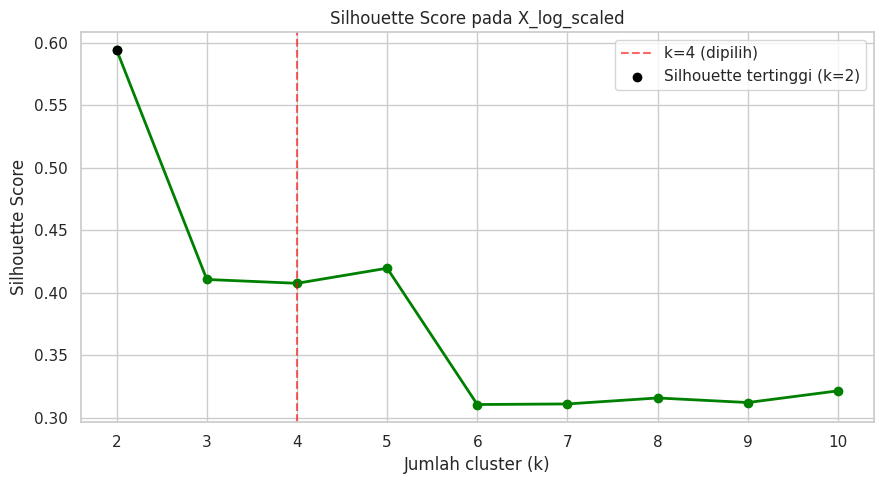

In [17]:
# Plot grafik Silhouette Score terhadap k.
# Tentukan nilai k terbaik dengan mempertimbangkan hasil Elbow Method dan Silhouette
# Score, lalu jelaskan alasannya pada cell markdown di bawah.
plt.figure(figsize=(9, 5))
plt.plot(k_values, silhouette_scores, marker='o', linewidth=2, color='green')
plt.axvline(4, color='red', linestyle='--', alpha=0.6, label='k=4 (dipilih)')
plt.scatter([best_k_silhouette], [max(silhouette_scores)], color='black', zorder=5,
            label=f'Silhouette tertinggi (k={best_k_silhouette})')
plt.title('Silhouette Score pada X_log_scaled')
plt.xlabel('Jumlah cluster (k)')
plt.ylabel('Silhouette Score')
plt.xticks(k_values)
plt.legend()
plt.tight_layout()
plt.show()

**Pilihan k untuk K-Means: k = 4.**

Alasannya:
- **Elbow Method:** penurunan inertia terbesar terjadi dari k=2 ke k=3 (27,3%) dan k=3 ke k=4 (20,8%). Setelah k=4, penurunan menyusut ke 15,4% lalu ~11%, sehingga siku berada di sekitar k=3–4.
- **Silhouette Score:** nilai tertinggi secara global ada pada k=2 (0,5942), tetapi k=2 hanya memisahkan data menjadi "engagement rendah" dan "engagement tinggi" — terlalu kasar dan tidak informatif. Pada k≥3, skor k=3 (0,4106) dan k=4 (0,4075) hampir sama, sedangkan k=5 (0,4196) sedikit lebih tinggi tetapi menghasilkan cluster sangat kecil berisi 117 posting (1,7%).
- **Interpretasi:** k=4 memberikan empat tingkat engagement yang seimbang dan mudah diberi nama (low, reaction-only, high-engagement video, viral video), tanpa cluster yang terlalu kecil. Karena itu k=4 dipilih sebagai kompromi terbaik antara elbow, silhouette, dan interpretabilitas.

## 3.4 Model K-Means Final

In [18]:
# Latih model K-Means final dengan nilai k terbaik yang kalian pilih pada X_log_scaled.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
K_FINAL = 4
kmeans_final = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=10).fit(X_log_scaled)
labels_kmeans = kmeans_final.labels_
df_clean['cluster_kmeans'] = labels_kmeans

print('Ukuran cluster K-Means:', np.bincount(labels_kmeans))
print('Inertia model final    :', round(kmeans_final.inertia_, 2))

Ukuran cluster K-Means: [ 413 2269 3508  806]
Inertia model final    : 10434.08


In [19]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling):
# tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
# Gunakan median karena distribusi fitur sangat miring.
# Ini membantu menginterpretasikan karakteristik tiap cluster.
profile_cols = [
    'num_reactions', 'num_comments', 'num_shares', 'num_likes',
    'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys',
]

def show_cluster_profile(labels, title):
    tmp = df_clean.copy()
    tmp['cluster'] = labels
    jumlah = tmp.groupby('cluster').size().rename('jumlah')
    median = tmp.groupby('cluster')[profile_cols].median().round(2)
    mean = tmp.groupby('cluster')[profile_cols].mean().round(2)
    print(f'Profil median cluster {title}:')
    display(median.join(jumlah))
    print(f'Profil rata-rata cluster {title}:')
    display(mean.join(jumlah))

show_cluster_profile(labels_kmeans, 'K-Means')

print('Komposisi status_type per cluster K-Means (proporsi baris):')
display((pd.crosstab(labels_kmeans, df_clean['status_type'], normalize='index') * 100).round(1))

Profil median cluster K-Means:


,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,jumlah
cluster,,,,,,,,,,
0,349.0,1418.0,263.0,256.0,75.0,2.0,4.0,2.0,1.0,413
1,193.0,10.0,1.0,190.0,1.0,0.0,0.0,0.0,0.0,2269
2,17.0,0.0,0.0,17.0,0.0,0.0,0.0,0.0,0.0,3508
3,207.5,486.5,139.5,149.0,41.0,1.0,1.0,0.0,0.0,806


Profil rata-rata cluster K-Means:


,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,jumlah
cluster,,,,,,,,,,
0,573.15,2261.60,345.94,443.68,107.59,9.98,7.44,3.00,1.46,413
1,439.29,25.18,3.43,435.22,2.78,1.09,0.11,0.07,0.01,2269
2,21.26,1.91,0.51,20.99,0.16,0.06,0.02,0.02,0.01,3508
3,330.90,720.57,160.44,279.20,47.06,2.44,1.87,0.18,0.15,806


Komposisi status_type per cluster K-Means (proporsi baris):


status_type,link,photo,status,video
row_0,,,,
0,0.0,9.4,2.7,87.9
1,1.1,65.1,10.3,23.5
2,1.1,75.3,3.0,20.6
3,0.0,10.4,1.1,88.5


# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

In [20]:
# Hitung linkage matrix (scipy.cluster.hierarchy.linkage) dengan metode ward pada X_log_scaled.
# Dataset berisi sekitar 7.000 baris sehingga proses ini masih ringan dan tidak perlu sampling.
Z = linkage(X_log_scaled, method='ward')
print('Bentuk linkage matrix:', Z.shape)
print('Jarak penggabungan terakhir (3 teratas):', np.round(Z[-3:, 2], 4))

Bentuk linkage matrix: (6995, 4)
Jarak penggabungan terakhir (3 teratas): [ 70.9668  86.6626 178.1727]


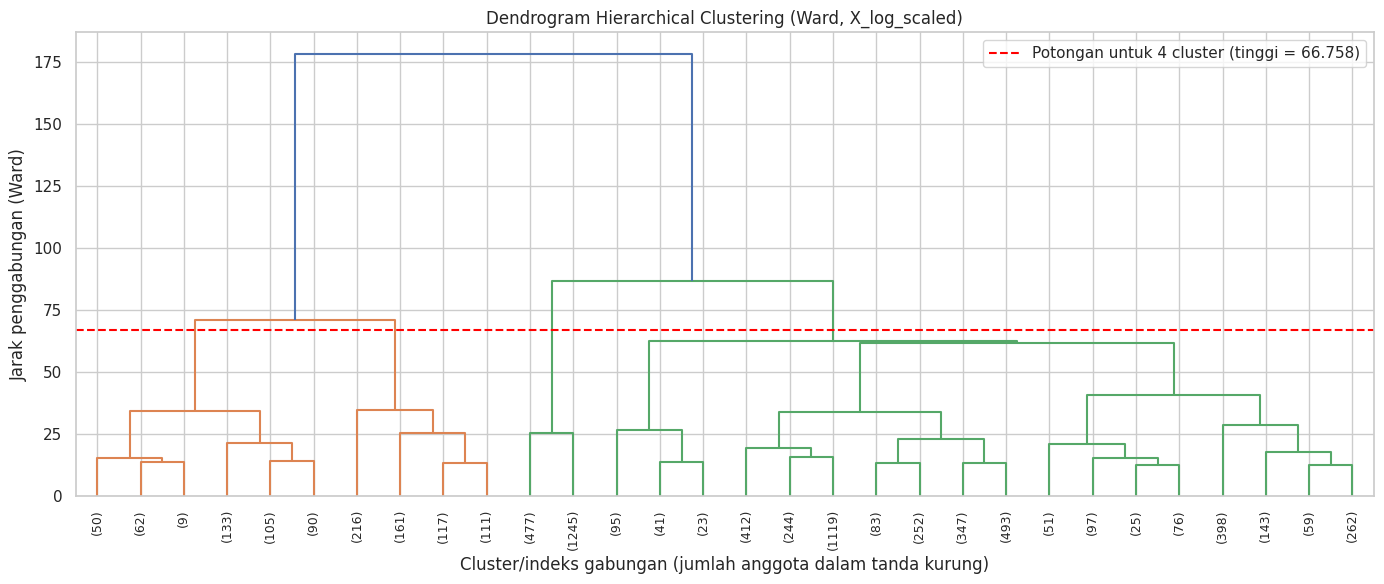

In [21]:
# Tampilkan dendrogram dari linkage matrix di atas.
# Batasi tampilan agar mudah dibaca (misalnya truncate_mode='lastp' atau p=30).
# Amati pada ketinggian berapa sebaiknya dendrogram dipotong untuk menentukan jumlah cluster.
cut_height = (Z[-4, 2] + Z[-3, 2]) / 2

plt.figure(figsize=(14, 6))
dendrogram(
    Z,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True,
    leaf_rotation=90,
    leaf_font_size=9,
)
plt.axhline(
    cut_height, color='red', linestyle='--',
    label=f'Potongan untuk {K_FINAL} cluster (tinggi = {cut_height:.3f})',
)
plt.title('Dendrogram Hierarchical Clustering (Ward, X_log_scaled)')
plt.xlabel('Cluster/indeks gabungan (jumlah anggota dalam tanda kurung)')
plt.ylabel('Jarak penggabungan (Ward)')
plt.legend()
plt.tight_layout()
plt.show()

## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [22]:
# Latih AgglomerativeClustering dengan masing-masing linkage (ward, complete, average, single).
# Gunakan jumlah cluster yang sama untuk semua linkage agar perbandingan adil.
linkage_methods = ['ward', 'complete', 'average', 'single']
linkage_predictions = {}
linkage_rows = []

for method in linkage_methods:
    model = AgglomerativeClustering(n_clusters=K_FINAL, linkage=method).fit(X_log_scaled)
    labels = model.labels_
    linkage_predictions[method] = labels
    sizes = np.bincount(labels)
    linkage_rows.append({
        'Linkage': method,
        'Ukuran cluster': ', '.join(map(str, sizes)),
        'Cluster terkecil': int(sizes.min()),
        'Silhouette': silhouette_score(X_log_scaled, labels),
        'Davies-Bouldin': davies_bouldin_score(X_log_scaled, labels),
        'Calinski-Harabasz': calinski_harabasz_score(X_log_scaled, labels),
    })

linkage_df = pd.DataFrame(linkage_rows)
display(linkage_df.style.format({
    'Silhouette': '{:.4f}',
    'Davies-Bouldin': '{:.4f}',
    'Calinski-Harabasz': '{:,.1f}',
}))

,Linkage,Ukuran cluster,Cluster terkecil,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,ward,"4220, 605, 1722, 449",449,0.2542,0.9919,"4,021.8"
1,complete,"639, 223, 6131, 3",3,0.5094,0.9755,"2,027.0"
2,average,"178, 6776, 39, 3",3,0.5947,0.6543,797.3
3,single,"6991, 2, 2, 1",1,0.6551,0.3209,29.1


**Pilihan linkage untuk Hierarchical Clustering: ward.**

Alasannya:
- **single linkage** menghasilkan satu cluster raksasa berisi 6.991 titik dan tiga cluster berisi 1–2 titik (chaining). Silhouette-nya terlihat tinggi (0,6551) justru karena cluster kecil sangat rapat, bukan karena segmentasi yang berguna.
- **average linkage** juga sangat tidak seimbang: 6.776 titik dalam satu cluster dan cluster lain berisi 3–39 titik.
- **complete linkage** masih menyisakan cluster berisi 3 titik dan satu cluster berisi 6.131 titik (87,6% data).
- **ward linkage** menghasilkan empat cluster yang jauh lebih seimbang (4.220, 1.722, 605, dan 449) dan paling mudah diinterpretasikan. Memang silhouette-nya lebih rendah (0,2542), tetapi angka itu tidak "ditipu" oleh cluster kecil seperti pada single/average. Ward juga memiliki Davies-Bouldin terbaik di antara linkage yang seimbang (0,9919).

## 4.3 Model Hierarchical Clustering Final

In [23]:
# Latih model AgglomerativeClustering final dengan linkage terbaik dan jumlah cluster
# yang sama dengan K-Means final.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
hc_final = AgglomerativeClustering(n_clusters=K_FINAL, linkage='ward').fit(X_log_scaled)
labels_hc = hc_final.labels_
df_clean['cluster_hc'] = labels_hc

print('Ukuran cluster Hierarchical (ward):', np.bincount(labels_hc))

Ukuran cluster Hierarchical (ward): [4220  605 1722  449]


In [24]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling):
# tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
show_cluster_profile(labels_hc, 'Hierarchical (ward)')

print('Komposisi status_type per cluster Hierarchical (proporsi baris):')
display((pd.crosstab(labels_hc, df_clean['status_type'], normalize='index') * 100).round(1))

Profil median cluster Hierarchical (ward):


,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,jumlah
cluster,,,,,,,,,,
0,81.0,6.0,0.0,78.0,0.0,0.0,0.0,0.0,0.0,4220
1,192.0,512.0,151.0,134.0,43.0,1.0,1.0,0.0,0.0,605
2,8.0,0.0,0.0,8.0,0.0,0.0,0.0,0.0,0.0,1722
3,321.0,1425.0,264.0,235.0,80.0,2.0,4.0,1.0,1.0,449


Profil rata-rata cluster Hierarchical (ward):


,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,jumlah
cluster,,,,,,,,,,
0,277.52,22.67,3.74,274.24,2.14,0.74,0.19,0.17,0.04,4220
1,238.10,748.73,173.51,184.05,49.83,2.47,1.44,0.18,0.13,605
2,8.58,0.30,0.30,8.49,0.07,0.02,0.00,0.00,0.00,1722
3,545.12,2292.80,357.51,414.62,111.22,9.16,7.19,1.80,1.13,449


Komposisi status_type per cluster Hierarchical (proporsi baris):


status_type,link,photo,status,video
row_0,,,,
0,1.1,72.0,7.9,19.0
1,0.0,4.3,0.5,95.2
2,0.9,68.2,1.3,29.6
3,0.0,0.7,0.0,99.3


# 5. Evaluasi Model

In [25]:
# Hitung metrik evaluasi INTERNAL untuk K-Means dan Hierarchical Clustering:
# Silhouette Score (semakin tinggi semakin baik), Davies-Bouldin Index (semakin rendah
# semakin baik), dan Calinski-Harabasz Score (semakin tinggi semakin baik).
# Sajikan dalam satu tabel perbandingan.
evaluation_rows = []
for name, labels in [
    ('K-Means', labels_kmeans),
    ('Hierarchical (ward)', labels_hc),
]:
    evaluation_rows.append({
        'Model': name,
        'Jumlah cluster': len(np.unique(labels)),
        'Silhouette': silhouette_score(X_log_scaled, labels),
        'Davies-Bouldin': davies_bouldin_score(X_log_scaled, labels),
        'Calinski-Harabasz': calinski_harabasz_score(X_log_scaled, labels),
    })

evaluation_df = pd.DataFrame(evaluation_rows)
display(evaluation_df.style.format({
    'Silhouette': '{:.4f}',
    'Davies-Bouldin': '{:.4f}',
    'Calinski-Harabasz': '{:,.1f}',
}))

,Model,Jumlah cluster,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means,4,0.4075,1.0176,"5,482.8"
1,Hierarchical (ward),4,0.2542,0.9919,"4,021.8"


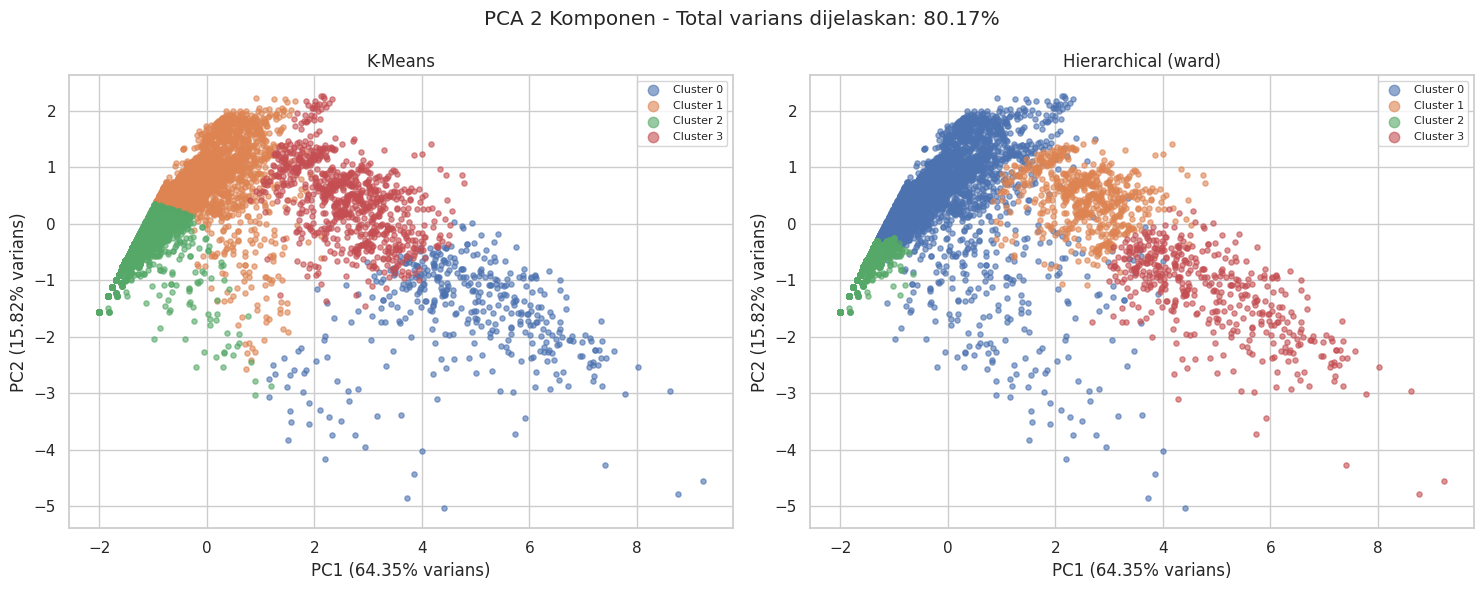

In [26]:
# Lakukan PCA ke 2 komponen pada X_log_scaled.
# Tampilkan scatter plot hasil clustering K-Means dan Hierarchical Clustering dalam satu
# baris subplot, diwarnai berdasarkan label cluster.
# Tampilkan juga persentase varians yang dijelaskan oleh kedua komponen PCA.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_log_scaled)
explained = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (name, labels) in zip(axes, [('K-Means', labels_kmeans), ('Hierarchical (ward)', labels_hc)]):
    for cluster in range(K_FINAL):
        mask = labels == cluster
        ax.scatter(
            X_pca[mask, 0], X_pca[mask, 1],
            s=14, alpha=0.6, label=f'Cluster {cluster}',
        )
    ax.set_title(f'{name}')
    ax.set_xlabel(f'PC1 ({explained[0]:.2%} varians)')
    ax.set_ylabel(f'PC2 ({explained[1]:.2%} varians)')
    ax.legend(markerscale=2, fontsize=8)

plt.suptitle(f'PCA 2 Komponen - Total varians dijelaskan: {explained.sum():.2%}')
plt.tight_layout()
plt.show()

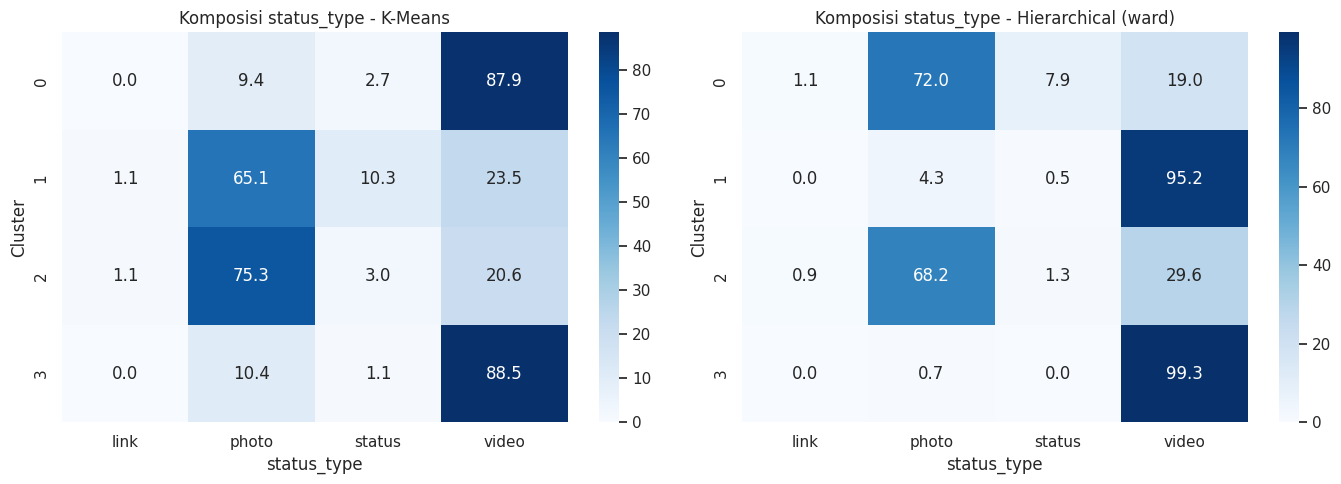

In [27]:
# Tampilkan komposisi status_type pada tiap cluster (crosstab dalam persen) untuk K-Means
# dan Hierarchical Clustering dalam bentuk heatmap, disusun dalam satu baris subplot.
# Ini hanya untuk membantu interpretasi cluster, bukan sebagai label asli.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, labels) in zip(axes, [('K-Means', labels_kmeans), ('Hierarchical (ward)', labels_hc)]):
    crosstab = pd.crosstab(labels, df_clean['status_type'], normalize='index') * 100
    sns.heatmap(crosstab, annot=True, fmt='.1f', cmap='Blues', ax=ax)
    ax.set_title(f'Komposisi status_type - {name}')
    ax.set_xlabel('status_type')
    ax.set_ylabel('Cluster')

plt.tight_layout()
plt.show()

# 6. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

**1. Pengaruh transformasi log dan feature scaling pada K-Means (bagian 3.1)**

Pada data mentah tanpa scaling, `num_comments` menyumbang sekitar **78,2%** total varians (varians 797.196, jauh di atas `num_positive` 204.317 dan `num_shares` 17.441). Akibatnya K-Means didominasi oleh komentar dan menghasilkan cluster yang sangat tidak seimbang: [6.392, 137, 467]. Setelah scaling saja, ukuran cluster menjadi [6.322, 388, 286], tetapi silhouette pada ruang log justru turun menjadi 0,2604 karena skew dan outlier yang ekstrem masih ada — scaling hanya menyamakan skala, tidak mengubah bentuk distribusi. Dengan `log1p` + scaling, ukuran cluster menjadi jauh lebih seimbang [990, 3.688, 2.318] dan silhouette naik menjadi **0,4106**. Ini membuktikan bahwa pada data hitungan yang sangat miring, transformasi log dan scaling **saling melengkapi**: log1p meredam outlier dan membuat distribusi lebih simetris, sedangkan scaling memastikan tidak ada fitur yang mendominasi jarak hanya karena satuannya lebih besar. Tanpa keduanya, centroid K-Means mudah tertarik oleh beberapa posting viral dan cluster menjadi tidak representatif.

**2. Penanganan kolom redundan dan sparse**

Enam kolom reaksi emoji hampir seluruhnya nol (60–94%), sedangkan `num_reactions` praktis sama dengan jumlah keenam kolom tersebut (99,87% baris identik, korelasi dengan `num_likes` = 0,995). Jika semua kolom dimasukkan, informasi yang sama terhitung berkali-kali dan jarak antar titik didominasi oleh reaksi like. Karena itu `num_reactions` dan `num_likes` tidak dipakai secara terpisah; reaksi dikelompokkan menjadi `num_positive` (likes + loves + wows), `num_hahas` (humor), dan `num_negative` (sad + angry). Hasilnya, proporsi nol turun menjadi 1,7% (`num_positive`), 30,2% (`num_comments`), 55,8% (`num_shares`), 84,0% (`num_hahas`), dan 88,7% (`num_negative`). Dengan demikian informasi jenis reaksi tetap terwakili, tetapi tidak ada fitur yang redundan dengan total reaksi. `num_comments` dan `num_shares` tetap dipisah karena mengukur diskusi dan penyebaran yang berbeda.

**3. Jumlah cluster optimal (Elbow vs Silhouette)**

Elbow Method menunjukkan penurunan inertia terbesar pada k=2→3 (27,3%) dan k=3→4 (20,8%), lalu melandai menjadi 15,4% (k=4→5) dan sekitar 11% setelahnya. Siku karenanya berada di **k=3–4**. Silhouette Score justru mencapai maksimum global pada **k=2** (0,5942), lalu turun ke 0,4106 (k=3) dan 0,4075 (k=4); k=5 sedikit lebih tinggi (0,4196) tetapi membentuk cluster berisi 117 titik. Jadi kedua metode tidak sepenuhnya sepakat: silhouette menyukai pembagian dua kelompok besar, sedangkan elbow mengarah ke 3–4. Saya memilih **k=4** karena k=2 terlalu kasar (hanya memisahkan engagement rendah vs tinggi), k=4 masih berada di area siku, silhouette-nya hampir sama dengan k=3, dan keempat cluster cukup seimbang serta mudah diinterpretasikan. k=5 ditolak karena muncul cluster yang sangat kecil sehingga hasilnya kurang stabil.

**4. Perbandingan metode linkage**

| Linkage | Ukuran cluster | Cluster terkecil | Silhouette | Davies-Bouldin | Calinski-Harabasz |
|---|---|---|---|---|---|
| ward | 4.220, 605, 1.722, 449 | 449 | 0,2542 | 0,9919 | 4.021,8 |
| complete | 639, 223, 6.131, 3 | 3 | 0,5094 | 0,9755 | 2.027,0 |
| average | 178, 6.776, 39, 3 | 3 | 0,5947 | 0,6543 | 797,3 |
| single | 6.991, 2, 2, 1 | 1 | 0,6551 | 0,3209 | 29,1 |

Single linkage menunjukkan **chaining** klasik: satu cluster menyerap hampir semua titik, sisanya hanya 1–2 titik. Average dan complete juga sangat tidak seimbang. Silhouette dan Davies-Bouldin terlihat "bagus" pada single/average justru karena cluster kecil sangat rapat dan terpisah jauh, bukan karena segmentasinya bermakna; Calinski-Harabasz single linkage hanya 29,1, jauh di bawah linkage lain, yang mengonfirmasi bahwa pemisahannya tidak sehat. **Ward** dipilih karena menghasilkan empat cluster yang seimbang dan paling masuk akal secara substantif, dengan Davies-Bouldin terbaik di antara linkage yang tidak degenerate (0,9919). Dendrogram ward juga menunjukkan pemisahan besar antara kelompok engagement rendah dan kelompok video berkomentar tinggi, lalu pemisahan berikutnya di dalam masing-masing kelompok.

**5. K-Means vs Hierarchical Clustering**

| Metrik | K-Means | Hierarchical (ward) |
|---|---|---|
| Silhouette | **0,4075** | 0,2542 |
| Davies-Bouldin | 1,0176 | **0,9919** |
| Calinski-Harabasz | **5.482,8** | 4.021,8 |

K-Means unggul jelas pada Silhouette dan Calinski-Harabasz, sedangkan ward sedikit lebih baik pada Davies-Bouldin. Perbedaannya cukup signifikan pada Silhouette (+0,153) dan Calinski-Harabasz (+1.461). Penyebabnya, K-Means mengoptimalkan jarak ke centroid sehingga menghasilkan cluster yang relatif kompak dan seimbang, sedangkan ward pada data ini membagi kelompok engagement rendah menjadi dua cluster besar dan kelompok video menjadi dua cluster, sehingga batas antar-cluster kurang tegas di ruang fitur. Meskipun begitu, kedua metode sepakat pada pola utama: cluster beranggotakan banyak video dengan komentar dan share tinggi terpisah dari cluster photo/status dengan engagement rendah. PCA 2 komponen menjelaskan **80,17%** varians (PC1 64,35%, PC2 15,82%), dan plot PCA menunjukkan pemisahan yang lebih rapi untuk K-Means, terutama pada sumbu PC1 yang merepresentasikan intensitas engagement.

**6. Karakteristik dan penamaan cluster**

K-Means (k=4), berdasarkan median pada data asli:
- **Cluster 0 — "Video viral / diskusi tinggi"** (413 posting; 87,9% video): median 349 reaksi, 1.418 komentar, 263 share. Kelompok paling ekstrem; posting video yang memicu diskusi dan penyebaran masif.
- **Cluster 1 — "Reaction-only"** (2.269 posting; 65,1% photo): median 193 reaksi tetapi hanya 10 komentar dan 1 share. Banyak yang menyukai, tetapi hampir tidak ada diskusi.
- **Cluster 2 — "Low engagement"** (3.508 posting; 75,3% photo): median 17 reaksi, 0 komentar, 0 share. Kelompok terbesar; posting yang nyaris tidak mendapat respons.
- **Cluster 3 — "Video engagement tinggi"** (806 posting; 88,5% video): median 207,5 reaksi, 486,5 komentar, 139,5 share. Video dengan diskusi dan share tinggi, tetapi belum seviral cluster 0.

Hierarchical ward (k=4) menemukan struktur serupa dengan pembagian yang sedikit berbeda:
- **Cluster 0 — "Low engagement"** (4.220; 72,0% photo): median 81 reaksi, 6 komentar, 0 share.
- **Cluster 1 — "Video engagement tinggi"** (605; 95,2% video): median 192 reaksi, 512 komentar, 151 share.
- **Cluster 2 — "Very low engagement"** (1.722; 68,2% photo): median 8 reaksi, 0 komentar, 0 share.
- **Cluster 3 — "Video viral"** (449; 99,3% video): median 321 reaksi, 1.425 komentar, 264 share.

Pada kedua model, **cluster video** memiliki komentar dan share jauh lebih tinggi daripada cluster photo/status, sedangkan **cluster photo** mendominasi kelompok engagement rendah. Perbedaan utamanya: K-Means memisahkan "video engagement tinggi" dari "video viral" dan memisahkan "reaction-only" dari "low engagement"; ward lebih dulu memisahkan engagement rendah vs tinggi, lalu membelah masing-masing menjadi dua. Komposisi `status_type` mendukung interpretasi ini: cluster viral K-Means 87,9% video, cluster low engagement 75,3% photo.

**7. Kelebihan dan kekurangan masing-masing metode**

- **K-Means:** cepat dan skalabel (O(n·k·d) per iterasi), mudah diimplementasikan, cluster cenderung kompak dan seimbang. Kekurangan: harus menentukan k di awal, mengasumsikan cluster berbentuk bola dengan varians serupa, sensitif terhadap inisialisasi dan outlier (karena itu perlu `n_init` dan transformasi log), serta tidak bisa menangani cluster dengan bentuk/ kepadatan berbeda.
- **Hierarchical (ward):** tidak perlu menentukan k untuk melihat struktur lengkap (dendrogram), deterministik, dan dapat menangkap struktur bersarang. Kekurangan: membutuhkan memori dan waktu O(n²) sehingga mahal untuk data besar, pilihan linkage sangat memengaruhi hasil, dan ward tetap mengasumsikan cluster berbentuk kompak; single linkage rentan chaining.
- **Praktis:** untuk dataset ini K-Means lebih cocok karena data besar (~7.000), cluster yang dihasilkan lebih seimbang, dan metrik internalnya lebih baik. Hierarchical tetap berguna untuk memvalidasi struktur dan melihat hierarki engagement.

# 7. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

## Kesimpulan

1. **Preprocessing sangat menentukan.** Data engagement sangat miring dan memiliki outlier ekstrem. Kombinasi `log1p` + `StandardScaler` meningkatkan kualitas cluster K-Means secara nyata: ukuran cluster menjadi seimbang [990, 3.688, 2.318] dan Silhouette Score 0,4106, jauh lebih baik daripada data mentah [6.392, 137, 467] (silhouette 0,3429) maupun data yang hanya di-scaling [6.322, 388, 286] (silhouette 0,2604).
2. **Redundansi harus dihilangkan.** `num_reactions` hampir identik dengan jumlah seluruh reaksi (99,87%) dan sangat berkorelasi dengan `num_likes` (0,995). Reaksi emoji yang sparse digabung menjadi `num_positive`, `num_hahas`, dan `num_negative`; `num_comments` dan `num_shares` dipertahankan karena mengukur engagement yang berbeda.
3. **k optimal adalah 4.** Elbow Method menunjukkan siku di k=3–4, sedangkan Silhouette Score global maksimum di k=2. k=2 terlalu kasar, k=5 menghasilkan cluster kecil (117 titik), sehingga k=4 dipilih sebagai kompromi terbaik yang seimbang dan interpretatif.
4. **Ward adalah linkage terbaik untuk kasus ini.** Single dan average linkage menghasilkan cluster sangat tidak seimbang (chaining), complete masih menyisakan cluster 3 titik. Ward menghasilkan empat cluster seimbang [4.220, 1.722, 605, 449] dan paling mudah diinterpretasikan.
5. **K-Means lebih unggul secara metrik internal** dibanding Hierarchical ward: Silhouette 0,4075 vs 0,2542 dan Calinski-Harabasz 5.482,8 vs 4.021,8; Davies-Bouldin keduanya berdekatan (1,0176 vs 0,9919). Keduanya sepakat bahwa video dengan komentar/share tinggi membentuk segmen tersendiri, sedangkan photo/status mendominasi segmen engagement rendah.
6. **Cluster dapat diberi nama:** "video viral/diskusi tinggi" (413 posting), "video engagement tinggi" (806), "reaction-only" (2.269), dan "low engagement" (3.508) untuk K-Means. Pola ini konsisten dengan median engagement dan komposisi `status_type`.

## Saran

1. **Pisahkan analisis sebelum dan sesudah 2016.** Reaksi emoji non-like baru muncul pada 2016, sehingga perilaku engagement sebelum dan sesudah periode itu berbeda. Clustering terpisah per periode (atau menambahkan fitur tahun) dapat menghasilkan segmen yang lebih homogen.
2. **Tambahkan fitur waktu**: jam, hari dalam minggu, dan bulan posting, karena waktu publikasi diduga memengaruhi engagement.
3. **Coba fitur rasio**, misalnya `num_comments / (num_positive + 1)` dan `num_shares / (num_positive + 1)`, untuk menangkap pola interaksi relatif dan mengurangi dominasi volume absolut.
4. **Bandingkan dengan algoritma lain** seperti DBSCAN, Gaussian Mixture Model, atau BIRCH yang dapat menangani bentuk cluster berbeda dan noise; DBSCAN khususnya berguna untuk menandai posting viral sebagai outlier.
5. **Uji stabilitas cluster** dengan beberapa nilai `random_state`/`n_init`, bootstrap, atau Adjusted Rand Index antar-run, serta **RepeatedKFold**-style resampling untuk memastikan k=4 tidak hanya optimal pada satu inisialisasi.
6. **Reduksi dimensi sebelum clustering** (PCA) atau **RobustScaler/QuantileTransformer** dapat dicoba untuk melihat apakah struktur cluster lebih stabil terhadap outlier ekstrem.
7. **Clustering per status_type** (misalnya khusus video) mungkin lebih tepat karena pola engagement photo dan video berbeda secara alami; `status_type` sebaiknya tetap tidak dipakai sebagai fitur, tetapi dapat dijadikan dasar stratifikasi eksperimen lanjutan.